# PART 1: IEEE-CIS Fraud Detection Data Exploration

### 1.1 Data Load and Class Imbalance overview

In order to conduct data exploration, pandas, numpy and matplotlib python libraries were imported.

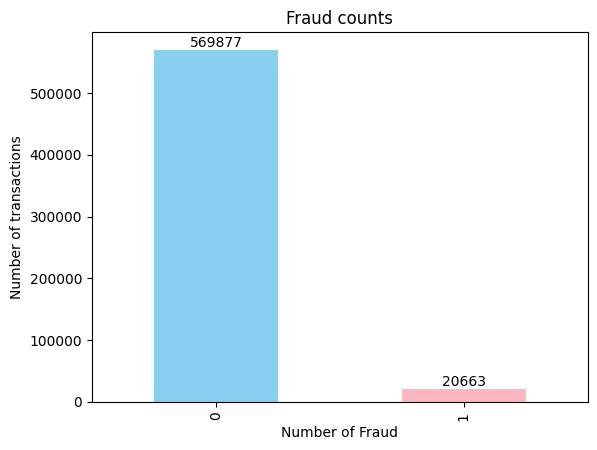

In [13]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Label Data Files
train_transaction = pd.read_csv("Data/train_transaction.csv")
train_identity = pd.read_csv("Data/train_identity.csv")

# Merging two databse by identity id by creating a new dataframe
df = train_transaction.merge(train_identity, on="TransactionID", how="left")

#checks
# print("Transaction:", train_transaction.shape)
# print("Identity:   ", train_identity.shape)
# print("Merged:     ", df.shape)

#Counting the fraud using Bar Chart
counts = df["isFraud"].value_counts()
colors = counts.index.map({0: "#89CFF0", 1: "#FFB6C1"})  # baby blue, light pink
fraud_bar = counts.plot(kind="bar", color=colors, title="Fraud counts", xlabel="Number of Fraud", ylabel="Number of transactions")
fraud_bar.bar_label(fraud_bar.containers[0])
plt.show()



Based on the output of Number of Fraud, there seem to be a small number of frauds where in the database there exist 20663 frauds and 569877 that are normal transactions. The percentage of fraud in this database is 3.5% (20663/569877). 

### 1.2 Transaction Amount Distribution

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64


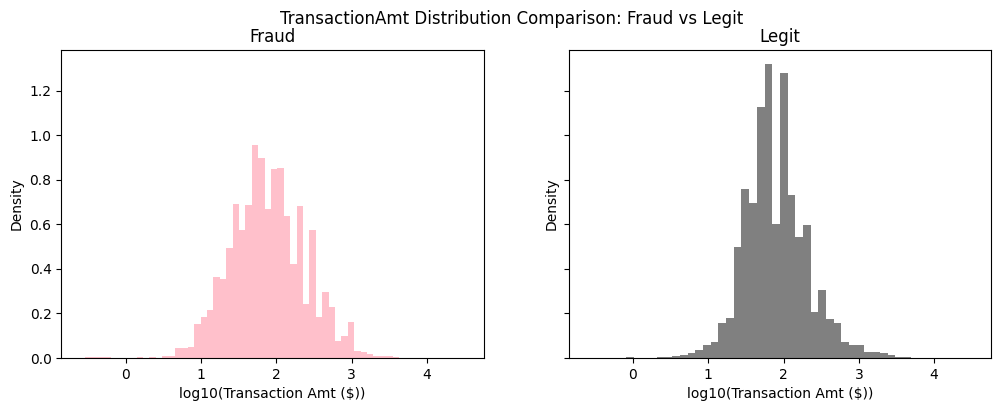

In [14]:
# see the transactionamt summary first
print(df["TransactionAmt"].describe())

# Ploting the histogram to see distribution
# np.log10(df["TransactionAmt"]).plot(kind="hist", bins=50, title="TransactionAmt (raw)", xlabel="Transaction Amount ($)")

fraud = df[df["isFraud"] == 1]
legit = df[df["isFraud"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

axes[0].hist(np.log10(fraud["TransactionAmt"]), bins=50, label="fraud", color="pink", density="true")
axes[1].hist(np.log10(legit["TransactionAmt"]), bins=50, label="legit", color="grey", density="true")
axes[0].set_title("Fraud")
axes[1].set_title("Legit")
axes[0].set_xlabel("log10(Transaction Amt ($))")
axes[1].set_xlabel("log10(Transaction Amt ($))")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density")

fig.suptitle("TransactionAmt Distribution Comparison: Fraud vs Legit")
plt.show()

### 1.3 Categorical Feature Analysis

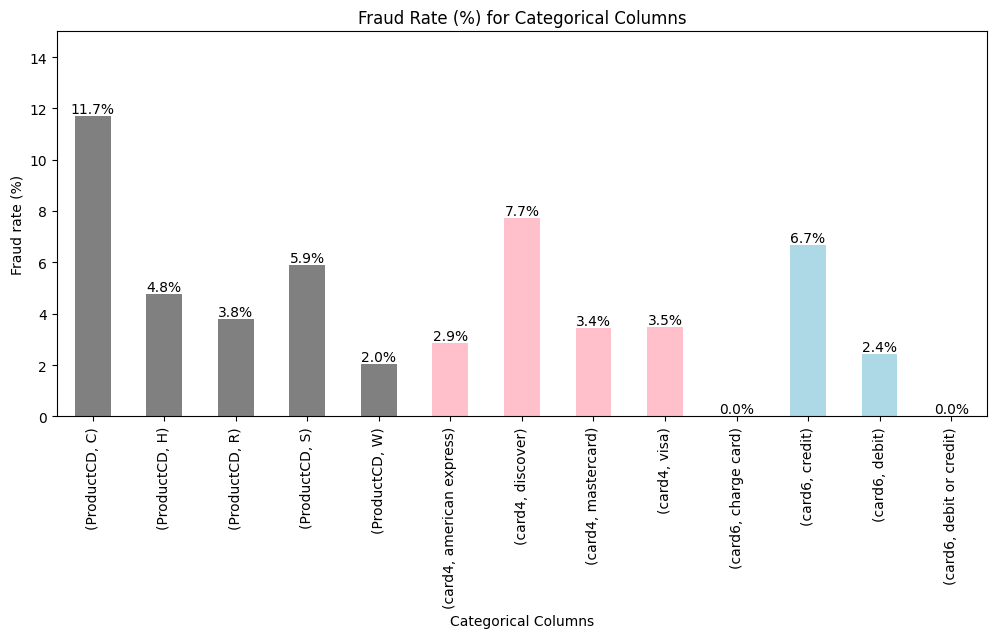

In [15]:
#The 3 categorical columns 
product_fraud_rate = df.groupby("ProductCD")["isFraud"].mean() * 100
card4_fraud_rate = df.groupby("card4")["isFraud"].mean() * 100
card6_fraud_rate = df.groupby("card6")["isFraud"].mean() * 100

product_fraud_rate = product_fraud_rate.round(2)
card4_fraud_rate = card4_fraud_rate.round(2)
card6_fraud_rate = card6_fraud_rate.round(2)

# creating a table
fraud_rates = pd.concat([product_fraud_rate, card4_fraud_rate, card6_fraud_rate],
                      keys=["ProductCD", "card4", "card6"])

#bar Chart
colors = ["grey"] * len(product_fraud_rate) + ["pink"] * len(card4_fraud_rate) + ["lightblue"] * len(card6_fraud_rate)
cat_bar = fraud_rates.plot(kind = "bar", color = colors, figsize=(12, 5), 
                          title = "Fraud Rate (%) for Categorical Columns", 
                          xlabel = "Categorical Columns", 
                          ylabel = "Fraud rate (%)")
cat_bar.set_ylim(0, 15)
cat_bar.bar_label(cat_bar.containers[0], fmt="%.1f%%")
plt.show()


### 1.4 Missing Data Analysis

In [16]:
fraud = df[df["isFraud"] == 1]
legit = df[df["isFraud"] == 0]


miss_all   = df.isna().mean() * 100
miss_fraud = fraud.isna().mean() * 100
miss_legit = legit.isna().mean() * 100

miss_all = miss_all.round(2)
miss_fraud = miss_fraud.round(2)
miss_legit = miss_legit.round(2)

# print(miss_all)

empty_table = pd.DataFrame({
    "% Empty For Each Column" : miss_all, 
    "% Empty That Were Fraud" : miss_fraud, 
    "% Empty That Were Non-Fraud" : miss_legit
})

empty_table = empty_table[empty_table["% Empty For Each Column"] > 90]

empty_table


,% Empty For Each Column,% Empty That Were Fraud,% Empty That Were Non-Fraud
dist2,93.63,81.94,94.05
D7,93.41,71.98,94.19
id_07,99.13,97.94,99.17
id_08,99.13,97.94,99.17
id_18,92.36,81.92,92.74
id_21,99.13,97.94,99.17
id_22,99.12,97.94,99.17
id_23,99.12,97.94,99.17
id_24,99.20,98.05,99.24
id_25,99.13,97.98,99.17


### 1.5 Anonymized Feature Correlation Analysis

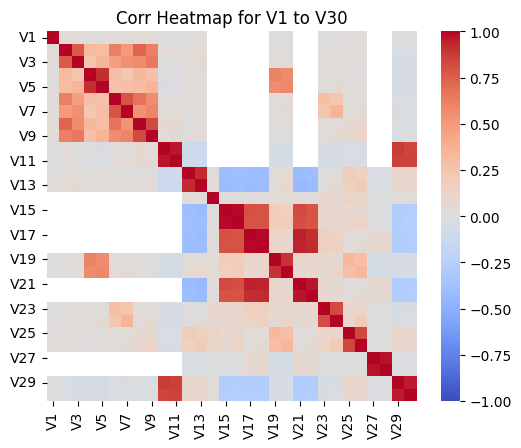

In [17]:
import seaborn as sns
v_subset = [f"V{i}" for i in range (1, 31)]

sns.heatmap(df[v_subset].corr(), cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.title("Corr Heatmap for V1 to V30")

plt.show()



In [18]:
v_all = [f"V{i}" for i in range (1, 340)]

v_table = pd.DataFrame({
    "Corr with isFraud": df[v_all].corrwith(df["isFraud"]),
    "Fraud mean":        fraud[v_all].mean(),
    "Non-fraud mean":    legit[v_all].mean(),
})
v_table = v_table.reindex(v_table["Corr with isFraud"].abs().sort_values(ascending=False).index)
v_table.head(10).round(2)

,Corr with isFraud,Fraud mean,Non-fraud mean
V257,0.38,2.96,1.11
V246,0.37,2.49,1.07
V244,0.36,1.99,1.04
V242,0.36,1.93,1.04
V201,0.33,2.75,1.02
V200,0.32,2.48,1.00
V189,0.31,1.87,0.97
V188,0.30,1.71,0.96
V258,0.30,3.40,1.17
V45,0.28,2.21,1.08


### 1.6 Part 1 Summary of Findings